# Lab 6: Simple Linear Regression and Statistical Modelling

This lab will give you a chance to practice and experiment with:
* Modeling data with simple linear regression
* Using both scikit-learn and statsmodels for regression
* Extracting MATH 216/227-style information (like confidence intervals and diagnostic plots for regression) in Python
* Understand more advanced features of regression: getting RSE, using transformations, etc



## Preliminaries

As a few quick reminders:
* You should be able to do questions 1-2 by Monday 
* Make sure your code exactly conforms to specifications (e.g. exactly matching variable names)
* Make sure your code works with any provided test code, and do NOT modify that test code unless explicitly stated
* When answering a specific question, ensure that all your data is within the relevant block.  For text-based answers, you will be asked to edit a specific markdown cell.  For code-based answers, please make sure all code is wholly contained within the relevant  `BEGIN` and `END` comments.
* Please be sure to run the first cell (to import libraries) any time you work on your code.  Please be sure to run all cells, from start to finish, before you submit.  Make sure they run without error, that all provided tests pass, etc.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats

# Question 1: Practice with Simple Linear Regression

This question uses data from [Scott Janish](https://scottjanish.com/relationship-of-abv-to-beer-scores/) summarizing information on beers.  This is based on a data set that looked at about 4.7 million beer reviews on Beeradvocate.  These were then condensed to look at beer ABV (alcohol by volume, which measures a beer's strength) and the average rating on Beeradvocate (1-5) for approximately 100 types of beer.  I have modified some of this data to focus in on a particular cluster.

In [2]:
beer_df = pd.read_csv("beerdat.csv")
beer_df.head()

,Category,ABV,Rating
0,Low Alcohol Beer,0.96,2.50
1,Kvass,1.07,3.19
2,American Pale Lager,5.16,3.31
3,American Amber / Red Lager,5.36,3.36
4,Euro Dark Lager,5.20,3.37


1a: What categories of beer have the lowest and highest rating?  What is the range of ABV in the data set?

In [4]:
# BEGIN QUESTION 1a
lowest_category = beer_df.loc[beer_df["Rating"].idxmin()]["Category"]
highest_category = beer_df.loc[beer_df["Rating"].idxmax()]["Category"]

abv_min = beer_df["ABV"].min()
abv_max = beer_df["ABV"].max()
abv_range = abv_max - abv_min

print(lowest_category)
print(highest_category)
print(abv_range)
# END QUESTION 1a

Low Alcohol Beer
American Double / Imperial Stout
12.96


- Lowest rating beer category: Low Alcohol Beer
- Highest rating beer category: American Double / Imperial Stout
- Range of ABV: 12.96

1b: We want to see if beer ABV predicts beer rating.  Use matplotlib to make an appropriate scatterplot of the data (with labeled axes).  Does a linear regression model seem reasonable?

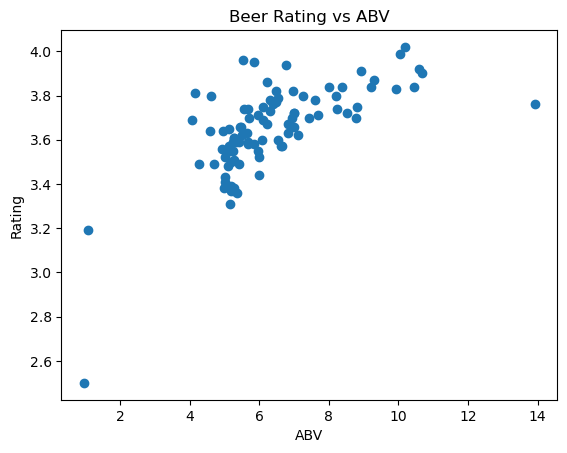

In [5]:
# BEGIN QUESTION 1b
plt.scatter(beer_df["ABV"], beer_df["Rating"])
plt.xlabel("ABV")
plt.ylabel("Rating")
plt.title("Beer Rating vs ABV")
plt.show()

# END QUESTION 1b

Data points follow a linear pattern by observation, meaning a linear regression model may seem reasonable.

1c: Use Scikit-Learn to fit a simple linear model.  Then give the equation of the least squares regression line you find.

In [8]:
# BEGIN QUESTION 1c
X = beer_df[["ABV"]]
y = beer_df["Rating"]

model = LinearRegression()
model.fit(X, y)

beta0 = model.intercept_
beta1 = model.coef_[0]

print(beta0, beta1)
# END QUESTION 1c

3.191197017799718 0.07177560758182062


1c: The least squares regression line is $$\hat{y} = 3.1912 + 0.0718(ABV).$$


1d: How do you interpret the slope?

The slope means that for each additional 1 unit increase in ABV, the predicted beer rating increases by about 0.0718 points on average.


1e: Dane Brammaj says "so strong beers really seem to do well.  I'm going to brew a beer with an ABV of 30 and it's going to be extremely popular.  Use `model.predict` to determine the predicted rating of Dane's beer. Do you trust this estimate?  Give at least one practical reason his answer makes no sense, and identify one precise statistical reason for why he is doing nonsense.

In [7]:
# BEGIN QUESTION 1d

pred_30 = model.predict(pd.DataFrame({"ABV": [30]}))[0]
pred_30

# END QUESTION 1d

np.float64(5.344465245254337)

1e: Using the model, the predicted rating for a beer with ABV 30 is about 5.34. I do not trust this estimate. Practically, a beer with 30% ABV is far outside the range of ordinary beers and would be very unusual. Statistically, this is extrapolation, since 30 is outside the range of ABV values in the observed data.


1f: One category of beer in this dataset had "Champagne" in the title.  What is the residual for this beer?  Save your answer as `resid` (as a float).

In [9]:
# BEGIN QUESTION 1f

beer_df["pred_rating"] = model.predict(beer_df[["ABV"]])
beer_df["residual"] = beer_df["Rating"] - beer_df["pred_rating"]

resid = float(
    beer_df.loc[
        beer_df["Category"].str.contains("Champagne", case=False, na=False),
        "residual"
    ].iloc[0]
)
# END QUESTION 1f


print(resid)

try:
    if -1 <= resid <= 1:
        print("Public test for 1f passed")
    else:
        print("Public test for 1f FAILED")
except:
    print("Public test for 1f FAILED")


0.010572075613532128
Public test for 1f passed


1g: Make a scatterplot showing both the data and your fitted line. Be sure that you have good axes labels, a title, and a key identifying your data and the fitted line.

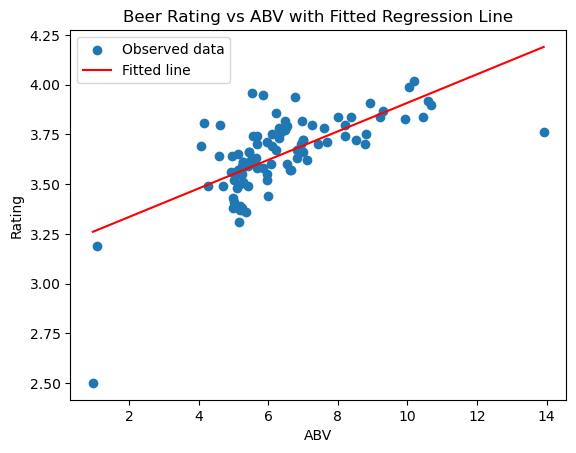

In [10]:
# BEGIN QUESTION 1g

x_vals = np.linspace(beer_df["ABV"].min(), beer_df["ABV"].max(), 200)
y_vals = model.predict(pd.DataFrame({"ABV": x_vals}))

plt.scatter(beer_df["ABV"], beer_df["Rating"], label="Observed data")
plt.plot(x_vals, y_vals, color="red", label="Fitted line")
plt.xlabel("ABV")
plt.ylabel("Rating")
plt.title("Beer Rating vs ABV with Fitted Regression Line")
plt.legend()
plt.show()

# END QUESTION 1g

1h: Use the scatterplot above to identify the point with the biggest residual (whether the error is positive or negative).  What category does it correspond to? Explain how you identified it. (You don't need to actually compute the residual: just give the category and explain how you identified it). 

In [11]:
# BEGIN QUESTION 1h
beer_df["abs_residual"] = np.abs(beer_df["residual"])
largest_resid_row = beer_df.loc[beer_df["abs_residual"].idxmax()]
largest_resid_category = largest_resid_row["Category"]
largest_resid_row
# END QUESTION 1h

Category        Low Alcohol Beer
ABV                         0.96
Rating                       2.5
pred_rating             3.260102
residual               -0.760102
abs_residual            0.760102
Name: 0, dtype: object

The point with the biggest residual appears to correspond to Low Alcohol Beer. I identified it as the point that is farthest vertically from the fitted regression line, since residuals measure vertical distance from the line.


# Question 2: Simulating Regression and Computing p-Values

In class, we simulated data where $Y=60+0.1X+\epsilon, \epsilon\sim N(0, 5).$  In that example, there was a meaningful relationship between mg of caffeine consumed and resting HR.

In this question, we'll simulate data when there's no actual relationship between two variables.

Suppose the total number of hours of sleep Dane gets a week ($Y$) is completly unrelated to the number of La Croix cans Dane has in his house that week ($X$).  It is thus modeled by $$Y=42+0\times X + \epsilon, \epsilon\sim N(0, 7).$$  That is, that the true value $\beta_1=0.$  

Dane, however, does not know this relationship and instead decides to run an experiment: over the next 20 weeks, he will store 10, 12, ..., 48 cans of La Croix in his house, and then see what his total weekly sleep is.   

2a: Write code below to simulate Dane's experiment: create a dataframe `sim_data` creating 20 observations (from x=10 to 48 inclusive, skipping by 2) from this model ($Y=42+\epsilon, \epsilon\sim N(0, 7)$).  Your final dataframe should have exactly 2 columns: one `x` giving the x values and one `sim_y` giving the simulated `y` values.  As a sanity check, the average of your simulate y values should be close to 42.

In [12]:
# Do NOT delete or change the seed
np.random.seed(42) # for consistency/reproducibility 

# BEGIN QUESTION 1h
x = np.arange(10, 50, 2)
sim_y = 42 + np.random.normal(0, 7, size=len(x))
sim_data = pd.DataFrame({"x": x, "sim_y": sim_y})

# END QUESTION 1h
try:
    if sim_data.size==40 and sim_data.iloc[1, 0]==12 and np.isclose(sim_data["sim_y"].mean(), 42, atol=3):
        print("Public test for 2a passed")
    else:
        print("Public test for 2a FAILED")
except:
    print("Public test for 2a FAILED")


print("Ignore the output of this upcoming test: it's a callibration check across machines")
try:
    if np.isclose(sim_data.iloc[0, 1], 45.476999, atol=0.01):
        print("Seeds Match")
    else:
        print("Seeds don't Match")
except:
    print("Seeds don't Match")
    

sim_data.head()


Public test for 2a passed
Ignore the output of this upcoming test: it's a callibration check across machines
Seeds Match


,x,sim_y
0,10,45.476999
1,12,41.032150
2,14,46.533820
3,16,52.661209
4,18,40.360926


2b: Fit a linear model to the data and call it `model`.  What do you find for $\hat{\beta}_0$ and $\hat{\beta}_1$?  

In [13]:
# Use this cell to find beta-hats:
X = sim_data[["x"]]
y = sim_data["sim_y"]

model = LinearRegression()
model.fit(X, y)
# BEGIN QUESTION 2b


# END QUESTION 2b
print("beta-hat-0: ", model.intercept_)
print("beta-hat-1: ", model.coef_)

beta-hat-0:  50.90673294317827
beta-hat-1:  [-0.34847665]


2c: Make a scatterplot showing the underlying data and your fitted line.

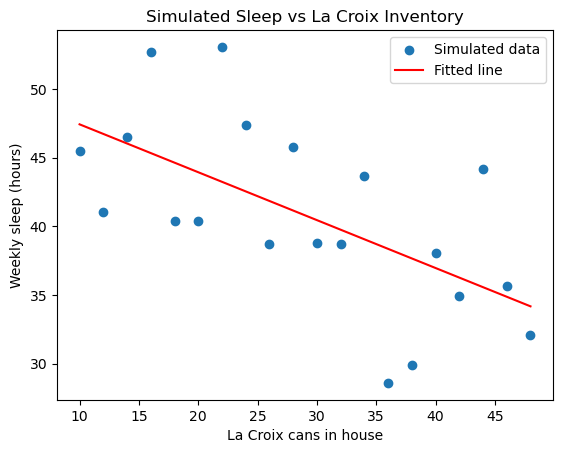

In [14]:
# BEGIN QUESTION 2c
x_line = np.linspace(sim_data["x"].min(), sim_data["x"].max(), 200)
y_line = model.predict(pd.DataFrame({"x": x_line}))

plt.scatter(sim_data["x"], sim_data["sim_y"], label="Simulated data")
plt.plot(x_line, y_line, color="red", label="Fitted line")
plt.xlabel("La Croix cans in house")
plt.ylabel("Weekly sleep (hours)")
plt.title("Simulated Sleep vs La Croix Inventory")
plt.legend()
plt.show()
# END QUESTION 2c

 Dane sees that he got a fitted slope of about $\hat{\beta}_1=-0.35$ (Note: *hopefully* you got the same slope, but different versions of numpy might give different slopes.  It's totally fine if you did - just use whatever number you got in place of -0.35). He would like to run a hypothesis test, based on his data, to test if there is a relationship between his La Croix inventory.  Specifically, he wants to test $H_0: \beta_1=0$ against $H_a: \beta_1 \neq 0$, where $\beta_1$ is the true slope for predicting his weekly sleep (in hours) from his La Croix inventory.  He sets a significance level of $\alpha=0.05.$
 
Unfortunately, it's not easy to directly get a $p$-value using `Scikit Learn`. We can, however, get this quickly this using `statsmodels`.  Code to do this is provided for you below.

2d: Run the cell below to fit a model using `statsmodels` and see the output.  You should see information in the `coef` column that matches what you found in 2b, and you should find a $p$ value.  What is Dane's test statistic and $p$-value?  Do you reject or fail to reject the null hypothesis?  

In [15]:
# Fitting our model
size = X.shape[0]

# For statsmodels, we need to add an all-ones column for the intercept
Xint = sim_data.copy()
Xint["int"] = 1
model_sm = sm.OLS(y, Xint[["int", "x"]]).fit()

# Summary table and test statistics, CI, etc
model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sim_y   R-squared:                       0.376
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     10.87
Date:                Fri, 20 Mar 2026   Prob (F-statistic):            0.00401
Time:                        16:08:30   Log-Likelihood:                -61.245
No. Observations:                  20   AIC:                             126.5
Df Residuals:                      18   BIC:                             128.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
int           50.9067      3.299     15.430      0.000      43.976      57.838
x             -0.3485      0.106     -3.297      0.004      -0.571      -0.126
==============================================================================
Omnibus:                        0.333   Durbin-Watson:                   2.055
Prob(Omnibus):                  0.846   Jarque-Bera (JB):                0.489
Skew:                           0.195   Prob(JB):                        0.783
Kurtosis:                       2.341   Cond. No.                         84.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The test statistic is about -3.297 and the p-value is about 0.00401. Since the p-value is less than 0.05, we reject the null hypothesis.


Here is a function to get the p-value using scikitlearn.  Note that you pass in an underlying dataframe with a column `x` and a column `sim_y`.  Don't worry about this code - just make sure that you understand how to use the function, and that it matches your output from 2d.  **Critically**: We run this using our `sim_data` dataframe without having added any intercept column, like we needed to with statsmodels.

In [16]:
def get_pvalue(df):
    """df should have columns `x` and `sim_y`"""
    
    # Fit the model
    X = df[['x']]
    y = df['sim_y']
    model = LinearRegression().fit(X, y)
    
    # Get predictions
    predictions = model.predict(X)
    
    # Get n, degrees of freedom
    n = len(y)
    df = n - 2          

    # Some janky math to get the test statistic
    # First we get the mse
    residuals = y - predictions
    rss = np.sum(residuals**2)
    mse = rss / df
    
    # Now we get a covariance matrix, which will give us the standard error
    X_matrix = np.column_stack((np.ones(n), X))
    cov_matrix = mse * np.linalg.inv(X_matrix.T @ X_matrix)
    standard_errors = np.sqrt(cov_matrix.diagonal())
    se_slope = standard_errors[1]
    
    # FINALLY we can get our test statistic and p-value
    # test statistic
    t_stat_slope = model.coef_[0] / se_slope
    
    # Benchmark against the relevant t distribution
    p_val_slope = 2 * (1 - stats.t.cdf(np.abs(t_stat_slope), df))
    
    return p_val_slope

get_pvalue(sim_data)

np.float64(0.004011896230832646)

2e: Now lets run a simulation as follows:
* For each of 5,000 simulation runs
 * Generate a new dataframe `sim_data` as in 2a: `sim_data` should have 20 observations (from x=10 to 48 inclusive, skipping by 2) from this model ($Y=42+\epsilon, \epsilon\sim N(0, 7)$).  It should have exactly 2 columns: one `x` giving the x values and one `sim_y` giving the simulated `y` values.  For each simulation run, you should have the same `x` data but different `sim_y` data (a new experiment for Dane!)
 * For each, use `get_pvalue` to get the corresponding $p$-value for the hypothesis test $H_0: \beta_1=0$ against $H_a: \beta_1 \neq 0$.
 * Store all 5,000 $p$-values in a list and compute the percent that are statistically significant, storing this as `percent_sig`
 
Write code to do the above simulation.  You might want to start with a smaller number of simulation runs as you test your code

In [18]:
# Include this line here, but NOT within your for loop
np.random.seed(42) # for consistency/reproducibility 
nruns = 5000
pvals = []
percent_sig = 0
b1=[]


# BEGIN QUESTION 2e
for _ in range(nruns):
    sim_data = pd.DataFrame({
        "x": np.arange(10, 50, 2),
        "sim_y": 42 + np.random.normal(0, 7, size=20)
    })
    pvals.append(get_pvalue(sim_data))
    temp_model = LinearRegression().fit(sim_data[["x"]], sim_data["sim_y"])
    b1.append(temp_model.coef_[0])

percent_sig = 100 * np.mean(np.array(pvals) < 0.05)

# END QUESTION 2e

print(percent_sig)

print(pvals[0:5])



5.46
[np.float64(0.004011896230832646), np.float64(0.3573234146348747), np.float64(0.3795915804797336), np.float64(0.736968113969612), np.float64(0.4156499634148192)]


2f: What percent were statistically significant?  Is this about what you'd expect?  Why or why not?

2f: About 5.46% of the simulations were statistically significant. This is about what we would expect, since the true null hypothesis is actually true here, so about 5% of tests should be significant just by chance when using $\alpha = 0.05$.


2g: Dane's first $p$-value was 0.00401.  Dane says "I got a statistically significant $p$-value, so there is a relationship between the amount of La Croix I have and my sleep hours!  However, we know that there is no relationship between his La Croix stock and sleep hours: all of the data was generated from a model where $\beta_1=0$!   How is it possible that he got a statistically significant result even when $\beta_1=0$?  What is the precise name for the error he would be making?

This is possible because random sample-to-sample variation can sometimes produce a statistically significant result even when the true slope is 0. If Dane concludes there is a relationship when in truth there is not one, he is making a Type I error.


2h: In our simulation, we did not store a list of all the $\hat{\beta}_1$'s we found along the way.  What would you expect (1) the mean of all the  $\hat{\beta}_1$'s from our 5,000 experiments to approximately be, and (2) what would you expect the standard deviation of all the  $\hat{\beta}_1$'s from our 5,000 experiments to approximately be?  Briefly explain your reasoning - and you might want to use a code cell or do some math for the standard deviation!  The formula for the standard error is in our slides, so you just have to compute it.

I would expect the mean of all the $\hat{\beta}_1$ values to be approximately **0**, because the true slope is 0 and the sampling distribution of $\hat{\beta}_1$ is centered at the true parameter.

I would expect the standard deviation of the $\hat{\beta}_1$ values to be about **0.136**. Using the standard error formula,
$$SE(\hat{\beta}_1)=\frac{\sigma}{\sqrt{\sum (x_i-\bar{x})^2}},$$
with $\sigma=7$ and $x=10,12,\dots,48$, we get
$$\sum (x_i-\bar{x})^2 = 2660,$$
so
$$SE(\hat{\beta}_1)=\frac{7}{\sqrt{2660}}\approx 0.136.$$
So the simulated slopes should be centered near 0 with a spread of about 0.136.


# Question 3: Regression with `statsmodels`

Let's load up a massive data set that has about 12,000 cars through 2017:

In [19]:
url = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv"
cars_df = pd.read_csv(url)
cars_df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


First, lets filter this down to cars from 2017, the most recent year in the data set, and remove any nans.

In [20]:
cars_df=cars_df[(cars_df["Year"]==2017) & 
                (cars_df["MSRP"].notna()) &
                (cars_df["Engine HP"].notna())
               ]
cars_df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
32,FIAT,124 Spider,2017,premium unleaded (recommended),160.0,4.0,MANUAL,rear wheel drive,2.0,Performance,Compact,Convertible,35,26,819,27495
33,FIAT,124 Spider,2017,premium unleaded (recommended),160.0,4.0,MANUAL,rear wheel drive,2.0,Performance,Compact,Convertible,35,26,819,24995
34,FIAT,124 Spider,2017,premium unleaded (recommended),160.0,4.0,MANUAL,rear wheel drive,2.0,Performance,Compact,Convertible,35,26,819,28195
50,BMW,2 Series,2017,premium unleaded (recommended),335.0,6.0,AUTOMATIC,all wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,31,21,3916,46450
51,BMW,2 Series,2017,premium unleaded (recommended),335.0,6.0,AUTOMATIC,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Convertible,32,21,3916,49050


In this question, we will carry out a full analysis (like in MATH 216/227!) to determine if there is a relationship between horsepower (`Engine HP`) and price (`MSRP`)

3a: Make a scatterplot of price vs horsepower.  Price should be on the y axis.  From this picture, we should be cautious of at least one of the conditions for inference.  Which condition for inference is likely not met?

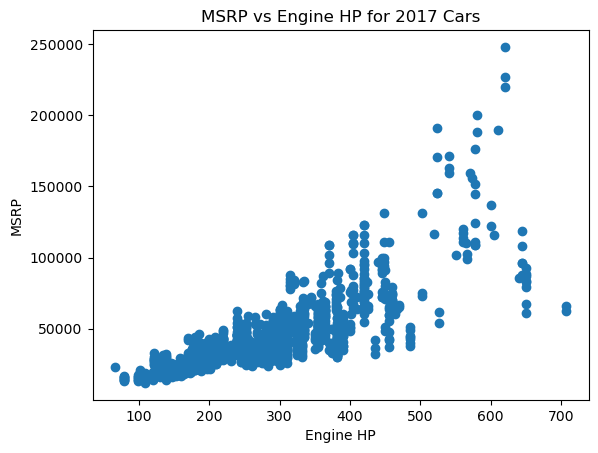

In [21]:
# BEGIN QUESTION 3a
plt.scatter(cars_df["Engine HP"], cars_df["MSRP"])
plt.xlabel("Engine HP")
plt.ylabel("MSRP")
plt.title("MSRP vs Engine HP for 2017 Cars")
plt.show()
# END QUESTION 3a

3a: The scatterplot shows a positive association between horsepower and MSRP, but there is clear fanning as horsepower increases. This suggests that the equal variance condition is likely not met.


3b: Set up a hypothesis test to determine if there is a relationship between horsepower (`Engine HP`) and price (`MSRP`).  Define your parameter in words and write out your hypotheses in mathematical notation.  Remember that you can use LaTeX to type math.  For instance, double click this cell to see how to type $\beta_1$, $\hat{y}$, and $H_0$.

3b: Let $\beta_1$ be the true slope in the population regression line for predicting MSRP from engine horsepower for 2017 cars. In words, $\beta_1$ measures the average change in predicted MSRP for a 1 horsepower increase.

We test
$$H_0:\beta_1=0$$
against
$$H_a:\beta_1 \neq 0.$$


3c: Fit a simple linear model using `statsmodels`.  In the subsequent markdown cell, identify (1) the equation of your LSRL, (2) the test statistic for your hypothesis, and (3) your $p$-value.  As above, be sure to use LaTeX to nicely type your equation with the proper symbols/notation. 

In [22]:
# BEGIN QUESTION 3c
X = cars_df[["Engine HP"]]
y = cars_df["MSRP"]

Xint = sm.add_constant(X)
model_sm = sm.OLS(y, Xint).fit()

model_sm.summary()
# BEGIN QUESTION 3c

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MSRP   R-squared:                       0.614
Model:                            OLS   Adj. R-squared:                  0.614
Method:                 Least Squares   F-statistic:                     2629.
Date:                Fri, 20 Mar 2026   Prob (F-statistic):               0.00
Time:                        16:18:23   Log-Likelihood:                -18238.
No. Observations:                1652   AIC:                         3.648e+04
Df Residuals:                    1650   BIC:                         3.649e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7314.7431   1034.812     -7.069      0.000   -9344.427   -5285.059
Engine HP    180.3348      3.517     51.270      0.000     173.436     187.234
==============================================================================
Omnibus:                      994.978   Durbin-Watson:                   0.646
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            19666.636
Skew:                           2.435   Prob(JB):                         0.00
Kurtosis:                      19.186   Cond. No.                         820.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The least squares regression line is
$$\hat{y} = -7314.7431 + 180.3348(\text{HP}).$$

The test statistic for the slope is **51.270**, and the p-value is essentially **0** (more precisely, it is extremely small, less than 0.001).


3d: Now lets check the conditions for inference.  Make a normal QQ plot and a residuals vs fitted values plot.  Then interpret them and assess if the conditions for inferene are met.  Hint: A lot of the code for these plots can be adapted from our code demos.

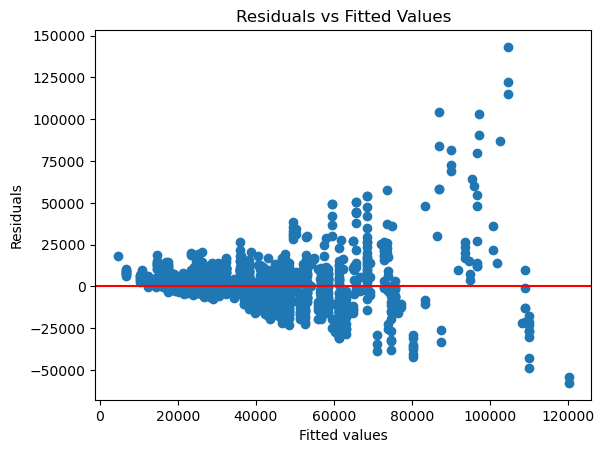

In [23]:
# Make your residual plot here
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

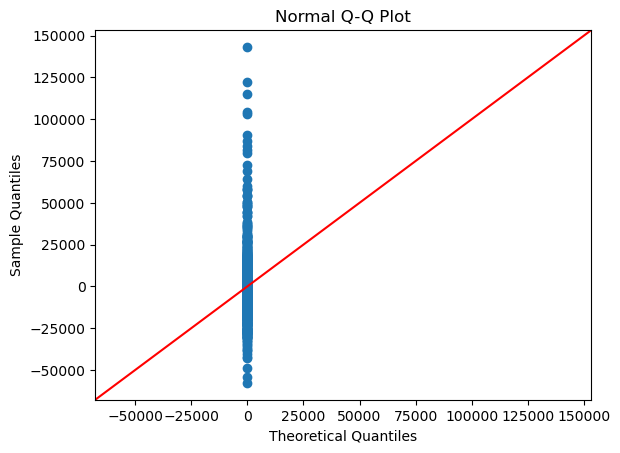

In [24]:
# Make your QQ plot here
sm.qqplot(model_sm.resid, line="45")
plt.title("Normal Q-Q Plot")
plt.show()

The residual plot shows non-constant spread and some structure, so the equal variance condition does not appear to be well met. The QQ plot also suggests departures from normality, especially in the tails. With such a large sample size, inference is somewhat robust, but the conditions are not perfectly satisfied.


3e: What are the $R^2$ and RSE values?  How do we interpret each?

In [26]:
# BEGIN QUESTION 3e
r_squared = model_sm.rsquared
RSE = np.sqrt(model_sm.mse_resid)
# BEGIN QUESTION 3e

print("R^2: ", r_squared)
print("RSE: ", RSE)

R^2:  0.6143644025610318
RSE:  15090.745142172236


The $R^2$ value is 0.6144, which means that about 61.44% of the variability in MSRP is explained by the linear relationship with horsepower. The RSE is 15090.75, which means the model’s predictions are typically off by about $15,091.


3f: Let's look at where the model is most off.  What car has the largest positive residual and what is the residual?  What car has the largest negative residual and what is the residual?  What are the MSRPs of these?  *Hint* You might want to look up the `np.idxmax` function (and observe that `model_sm.resid` appears to be a numpy array!)

In [29]:
# BEGIN QUESTION 3f
residuals = model_sm.resid

max_pos_idx = np.argmax(residuals)
max_neg_idx = np.argmin(residuals)

largest_pos_row = cars_df.iloc[max_pos_idx]
largest_neg_row = cars_df.iloc[max_neg_idx]

largest_pos_resid = residuals.iloc[max_pos_idx]
largest_neg_resid = residuals.iloc[max_neg_idx]

print("Largest positive residual:")
print(largest_pos_row)
print("Residual:", largest_pos_resid)

print("\nLargest negative residual:")
print(largest_neg_row)
print("Residual:", largest_neg_resid)


# BEGIN QUESTION 3f

Largest positive residual:
Make                                         Mercedes-Benz
Model                                              S-Class
Year                                                  2017
Engine Fuel Type               premium unleaded (required)
Engine HP                                            621.0
Engine Cylinders                                      12.0
Transmission Type                                AUTOMATIC
Driven_Wheels                             rear wheel drive
Number of Doors                                        2.0
Market Category      Factory Tuner,Luxury,High-Performance
Vehicle Size                                         Large
Vehicle Style                                  Convertible
highway MPG                                             21
city mpg                                                14
Popularity                                             617
MSRP                                                247900
Name: 8840, dtype: object
Res

The car with the largest positive residual is the 2017 Mercedes-Benz S-Class, with a residual of about 143226.82 and MSRP 247900. The car with the largest negative residual is the 2017 Dodge Challenger, with a residual of about -57686.97 and MSRP 62495.


# Question 4: A Quick Preview on Transformations

When we look at our original MSRP vs HP scatterplot, we might observe that the prices for some of the cars get very large, and we've also seen fanning indicating more variability as HP increases.  These suggest transforming the data.  One transformation that might fit well here is to take the log of the price, and fit a linear model for $$\ln(MSRP) \approx \beta_0 + \beta_1 \times HP.$$  Intuitively, taking the log will especially shrink the larger errors.  For instance:
* $\ln(10)\approx 2.3$
* $\ln(100)\approx 4.6$
* $\ln(1000) \approx 6.9$.

If we take the natural log of the price, our most extreme prices will still be the most extreme: but they'll be shrunk down substantially more, and hopefully be brought into a reasonable range.  Another way to think about this is exponential premiums: increasing the HP from 200 to 250 is meaningful in terms of typical performance and should increase the price.  Increasing it from 600 to 650 might put us  in the realm of vanity, and increase the price drastically.  In general, if we see this right fanning (where as X increases, the spread of Y increases), we might consider taking the log of the Y variable.  Note, however, that this will change our interpretation of the slope, since we're no longer regressing MSRP on HP.

4a: Add a new column `ln(MSRP)` to the dataframe and make a scatterplot of `ln(MSRP)` vs `Engine HP`.  Hint: you might google for how to get the natural log in numpy/pandas!  What do you observe about the scatterplot?

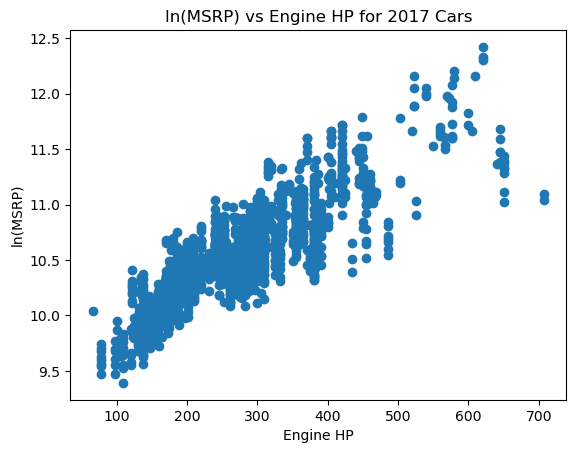

In [30]:
# BEGIN QUESTION 4a
cars_df["ln(MSRP)"] = np.log(cars_df["MSRP"])

plt.scatter(cars_df["Engine HP"], cars_df["ln(MSRP)"])
plt.xlabel("Engine HP")
plt.ylabel("ln(MSRP)")
plt.title("ln(MSRP) vs Engine HP for 2017 Cars")
plt.show()

# END QUESTION 4a

After taking the natural log of MSRP, the scatterplot looks more linear and the vertical spread is more even across horsepower values. The transformation reduces the impact of the most expensive cars and helps with the fanning seen in Question 3.


4b: Now fit a linear model for $\ln(MSRP) \approx \beta_0 + \beta_1 \times HP.$  What is the LSRL you find?

In [31]:
# BEGIN QUESTION 4b
X = cars_df[["Engine HP"]]
y = cars_df["ln(MSRP)"]

Xint = sm.add_constant(X)
model_sm = sm.OLS(y, Xint).fit()

model_sm.summary()

# BEGIN QUESTION 4b

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               ln(MSRP)   R-squared:                       0.717
Model:                            OLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     4177.
Date:                Fri, 20 Mar 2026   Prob (F-statistic):               0.00
Time:                        16:32:56   Log-Likelihood:                 3.4404
No. Observations:                1652   AIC:                            -2.881
Df Residuals:                    1650   BIC:                             7.939
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.5364      0.017    575.591      0.000       9.504       9.569
Engine HP      0.0036   5.63e-05     64.627      0.000       0.004       0.004
==============================================================================
Omnibus:                       14.498   Durbin-Watson:                   0.721
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               21.190
Skew:                           0.054   Prob(JB):                     2.50e-05
Kurtosis:                       3.544   Cond. No.                         820.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The least squares regression line is
$$\widehat{\ln(MSRP)} = 9.5364 + 0.0036(\text{HP}).$$


4c: Make a normal QQ plot, a residuals vs fitted values plot, and find the $R^2$ and RSE.  How do these compare to what you found in question 3?

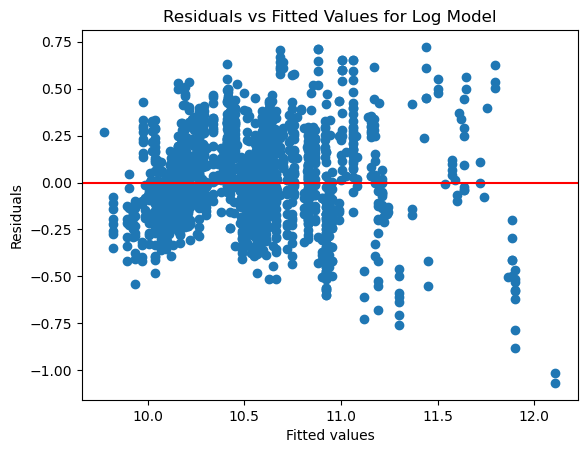

In [34]:
# Make your residual plot here
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values for Log Model")
plt.show()

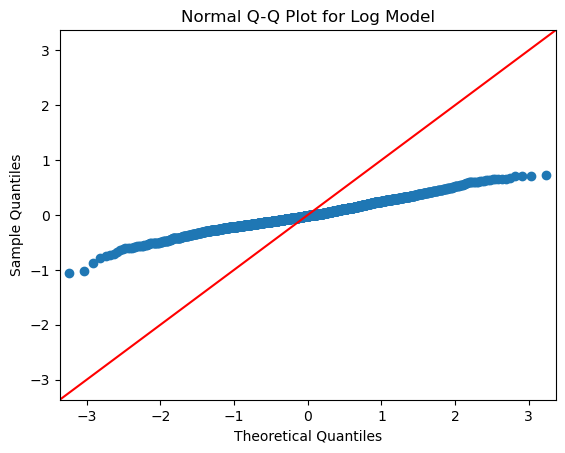

In [33]:
# Make your QQ plot here
sm.qqplot(model_sm.resid, line="45")
plt.title("Normal Q-Q Plot for Log Model")
plt.show()

In [32]:
# Get your RSE and r_squared here

# BEGIN QUESTION 4c
r_squared = model_sm.rsquared
RSE = np.sqrt(model_sm.mse_resid)
# BEGIN QUESTION 4c

print("R^2: ", r_squared)
print("RSE: ", RSE)

R^2:  0.7168189599849006
RSE:  0.2416136286934794


Compared with Question 3, the log-transformed model fits better overall. The residual plot is more even, with less fanning, and the QQ plot is closer to a straight line, so the regression conditions look more reasonable after the transformation. The $R^2$ is 0.7168, which is higher than before, so horsepower explains more of the variation in the log of price than in raw price. The RSE is 0.2416 on the log scale, meaning the typical prediction error is about 0.242 in $\ln(MSRP)$. Overall, the transformed model appears to be an improvement over the original model.


## Lab Check Hint for Lab 6

For this upcoming lab check, you should feel good about:
* The syntax for creating a simple linear model in `statsmodels` and with `scikitlearn`, as in question 1 and 3.  Pay specific attention for how the data needs to be formatted to use each (e.g. when you add an intercept column and not).
* Reading the output from statsmodels.  Specifically, identifying the LSRL, the test statistic and p-value for the slope, and the $R^2.$  You should also be able to identify the LSRL from `scikitlearn` output.
* Interpreting $R^2, RSE$, a residual plot, and a normal QQ plot.



# Submission Instructions: due 3/20 at 5pm

We will submit this lab as a PDF.
1. Hit "Kernel --> Restart & Run All"
2. Make sure that all of your cells run and that any output necessary for grading is shown.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  Note that this is a bit more involved than just saving as a PDF directly from Jupyter, but usually leads to better-formatted notebooks so **please follow this process exactly.**
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.  It is OK if certain tables are too wide (that's unavoidable) and it's fine if my code/instructions isn't fully visible, but I need to be able to read all of your code/comments/charts.
5. Upload that PDF to Gradescope.  If you run into any issues, please reach out to me before the deadline and document that you've completed everything (e.g. by emailing me a copy of your Jupyter notebook).